<h1 style="background: linear-gradient(to right, #395761, #7799B6);
           color: white;
           padding: 22px;
           border-left: 10px solid #CEEB13;
           text-align: center;
           font-family: 'Roboto Mono', Menlo, 'Courier New', monospace;
           font-weight: 600;">
  RLVR using GRPO
</h1>


Every notebook so far left the weights alone. Sampling, voting, scoring, and refinement all spent more compute at inference time and left the model as it was. This one changes the weights. The ingredients are already on the table: a model that can sample responses, a verifier that says whether a response is correct, and the per-token log-probabilities from the scoring notebook. Reinforcement learning combines them into a training loop, and **GRPO** (group relative policy optimization) is the simplest version of that loop that works on a single GPU.

The whole recipe has a name: **RLVR**, reinforcement learning with verifiable rewards. Reinforcement learning, because the model learns from rewards on its own attempts rather than from examples of correct answers; verifiable, because the reward comes from a program that checks the answer, not from a person or a learned judge. RLVR says where the reward comes from. GRPO is the algorithm that turns those rewards into weight updates.

By the end of this notebook you will:

1. See what RLVR is and how a verifier replaces the human feedback of classic RL for language models,
2. Sample a group of responses to one problem and reward each with the verifier,
3. Turn rewards into advantages by comparing within the group,
4. Score each response with its sequence log-probability, with gradients attached,
5. Write the GRPO loss and watch one update move the probabilities the right way,
6. Train the base model for one hundred steps on one GPU and measure it on MATH-500.

Every function in the training loop is written here. The charts come from `reasoning_utils/plots.py`.

## `Step 1`: From inference time to training time

Reinforcement learning for a language model is a short loop: the model answers, something scores the answer, and the weights move toward whatever scored well. In the original recipe the "something" was people. Human raters ranked responses, a second model was trained to imitate their rankings, and that **reward model** scored every new response during training. It worked, and it was slow and expensive, because the reward model is itself a large network trained on labels that cost money.

For reasoning the reward can be a program. A math problem has a reference answer; the verifier from the evaluation stage compares a response to it and returns correct or incorrect, instantly and for free. **Reinforcement learning with verifiable rewards (RLVR)** keeps the loop and swaps the judge. The name says exactly what changes: the reward is verifiable, computed by a check that anyone can rerun, so there is nothing to label and no judge to train.

<div align="center"><img src="assets/rlhf-vs-rlvr.svg" alt="Two reinforcement learning loops side by side. Top: prompts go into the model, responses are ranked by people, a reward model is trained on the rankings and scores new responses, the weights are updated. Bottom: the same loop with the math verifier in place of the people and the reward model, returning 1 for a correct boxed answer and 0 otherwise" width="1000"/></div>

| | RLHF: reward from people | RLVR: reward from a verifier |
|---|---|---|
| what judges a response | a reward model trained on human rankings | a program that checks the final answer |
| cost per judgment | a forward pass of a second large model | microseconds |
| can be wrong? | yes, it is a learned guess | only if the verifier is buggy |
| works for | anything people can rank | anything with a checkable answer: math, code, puzzles |

RLVR fixes the source of the reward and nothing else. Turning rewards into weight updates is the job of a policy gradient algorithm, and the one used here, as in the open reasoning models, is GRPO.

Some vocabulary, because the field uses it everywhere. The model being trained is the **policy**. A sampled response is a **rollout**. The number the judge returns is the **reward**. And the thing that makes GRPO *group relative*: for each problem the policy produces several rollouts, a **group**, and every rollout is judged against the others in its group rather than against an absolute scale. That comparison is what lets GRPO skip the extra value network that older algorithms needed.

## `Step 2`: Setup

The same base model, [Qwen3-0.6B-Base](https://huggingface.co/Qwen/Qwen3-0.6B-Base), compiled, because training runs hundreds of sampling loops and the compiled model samples about four times faster. One thing is new. The weights are stored in `bfloat16`, a format with only eight bits of precision, and a training step at a learning rate of 1e-5 wants to add something like 0.00001 to a weight of around 0.02. In `bfloat16` that addition rounds away to nothing:

In [1]:
import random

import torch

from reasoning_utils import (
    MATH_PROMPT,
    KVCache,
    avg_logprob,
    evaluate_math,
    generate_text,
    get_device,
    grade,
    last_boxed,
    load_math500,
    load_math_train,
    load_qwen3,
    peak_memory_gb,
    render_math_prompt,
    scale_by_temperature,
    top_p_filter,
)
from reasoning_utils.plots import (
    plot_accuracy_comparison,
    plot_advantage_patterns,
    plot_benchmark_composition,
    plot_bf16_resolution,
    plot_logprob_shift,
    plot_rewards_and_advantages,
    plot_sequence_logprob,
    plot_training_metrics,
)

device = get_device()
model, tokenizer = load_qwen3("base", device=device, compile=True)

device: cuda (NVIDIA L40S)


In [2]:
weight = torch.tensor(0.02, dtype=torch.bfloat16)
update = 1e-5

print("bfloat16:", (weight + update).item(), "changed:", (weight + update).item() != weight.item())
print("float32: ", (weight.float() + update).item())

bfloat16: 0.02001953125 changed: False
float32:  0.02002953179180622


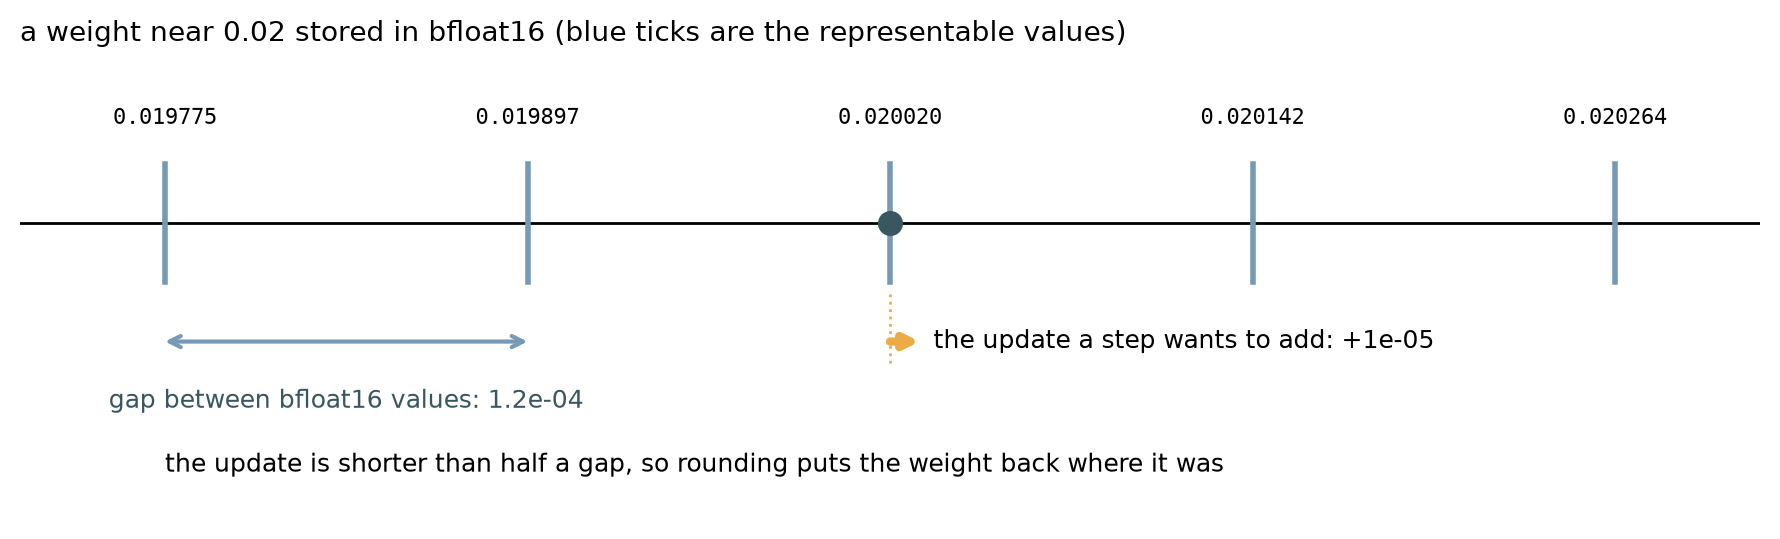

In [3]:
plot_bf16_resolution(weight=0.02, update=1e-5)

The representable numbers near 0.02 are about 0.0001 apart, ten times the update, so the weight snaps back to where it was and most of the training step is lost. The fix is one line: keep the weights in `float32` while training. The model takes twice the memory, which the L40S has to spare, and sampling runs at almost the same speed.

In [4]:
model = model.float()
print(next(model.parameters()).dtype)

torch.float32


The running example is the rectangle problem again, with the plain prompt, the one that ends in "Answer:" and asks for nothing else. Training uses that prompt too. If the model learns to show its work, it will be because the reward made working things out pay, not because the prompt asked for it.

In [5]:
problem = "A rectangle's length is 4 more than twice its width. Its perimeter is 50. What is its area?"
answer = "126"
example = {"problem": problem, "answer": answer}

prompt = render_math_prompt(problem, MATH_PROMPT)
prompt_len = len(tokenizer.encode(prompt))
print(prompt_len, "prompt tokens")

56 prompt tokens


Before touching the weights, the number to beat. The base model, greedy, on the first fifty problems of MATH-500, as in every notebook before this one. The `float32` copy rounds differently from the `bfloat16` model those notebooks used, so expect a baseline a couple of points away from their 20 percent:

In [6]:
N = 50
subset = load_math500()[:N]

results = {}
results["before training"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024)

10/50 correct so far: 3
20/50 correct so far: 4
30/50 correct so far: 4
40/50 correct so far: 7
50/50 correct so far: 8
accuracy: 16.0% (8/50)
average response: 121 tokens
time: 1.0 min


## `Step 3`: Training problems

Training on the benchmark would be cheating, so the training problems come from the MATH training split: 7,500 competition problems from the same source as MATH-500, with no overlap. The records carry a worked solution instead of a bare answer, and the reference answer is the last `\boxed{...}` in that solution, pulled out with the verifier's own `last_boxed`. The solutions themselves are never shown to the model. The point of reinforcement learning is that the model finds its own way to the answer.

In [7]:
math_train = load_math_train()
random.Random(0).shuffle(math_train)
print(len(math_train), "training problems")

7496 training problems


In [8]:
print(math_train[0]["problem"])
print("answer:", math_train[0]["answer"])

The measure of angle $ACB$ is 40 degrees. If ray $CA$ is rotated 480 degrees about point $C$ in a clockwise direction, what will be the positive measure of the new acute angle $ACB$, in degrees?

[asy]
draw((0,0)--dir(40),linewidth(1),Arrow);
draw((0,0)--dir(0),linewidth(1),Arrow);
dot(.8dir(40));
dot(.8dir(0));
dot((0,0));
label("A",.8dir(40),NW);
label("B",.8dir(0),S);
label("C",(0,0),W);
[/asy]
answer: 80


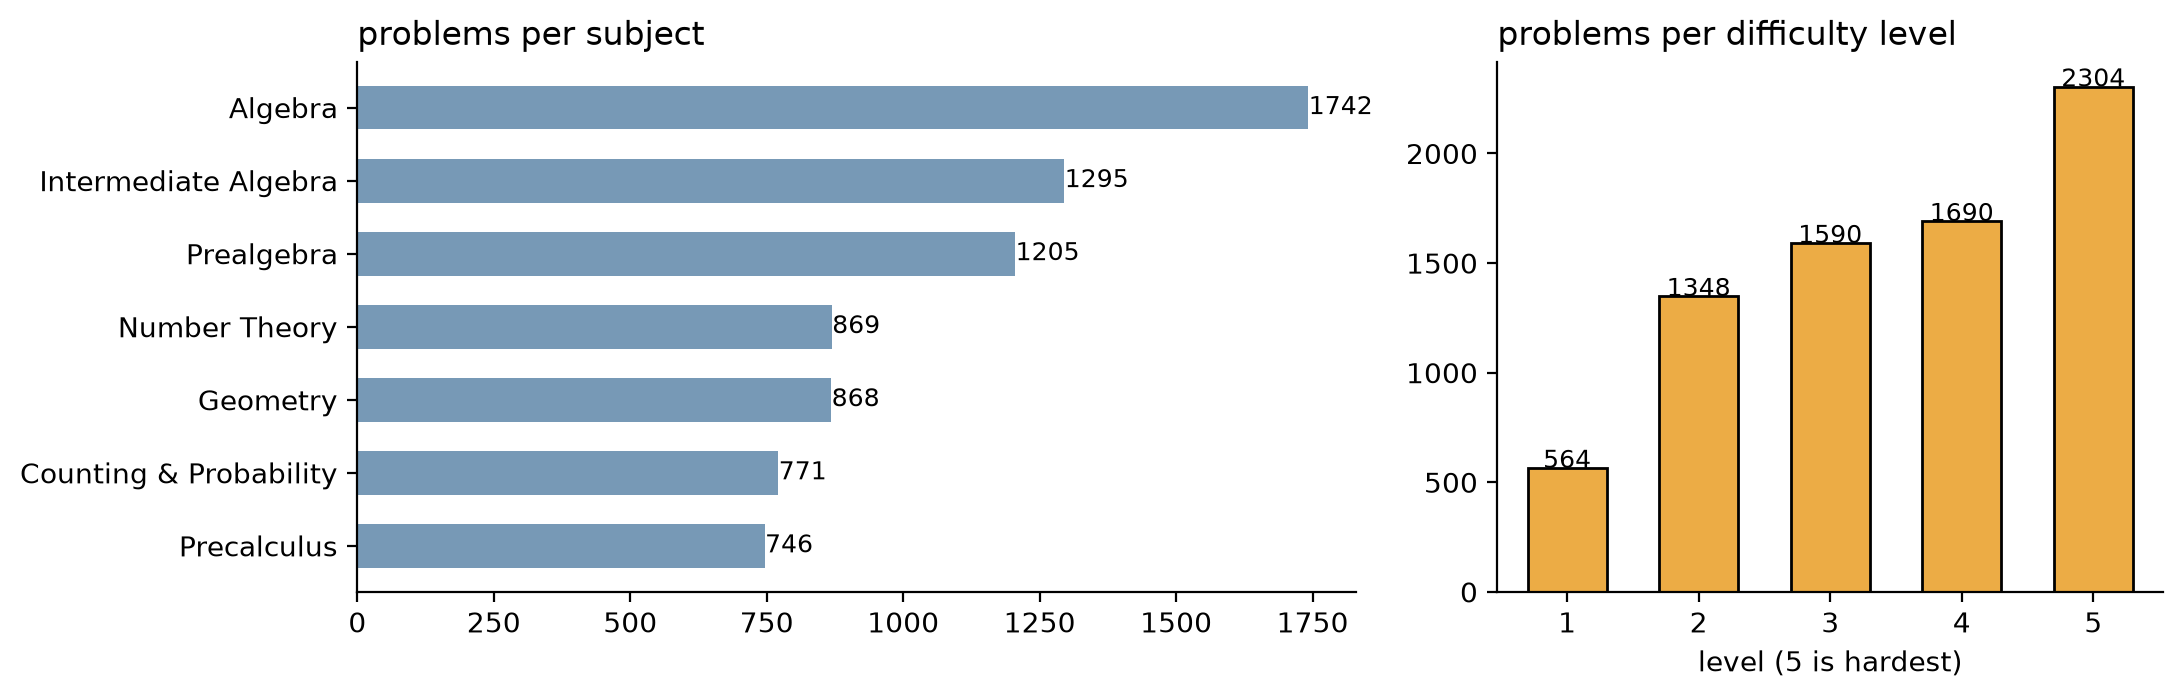

In [9]:
plot_benchmark_composition(math_train)

The same seven subjects and five difficulty levels as the benchmark, and a heavier tail of hard problems. Only two fields are used from here on: `problem` and `answer`.

## `Step 4`: Rollouts

One GRPO step works on **one problem**: sample a group of responses to it, reward each, compare them within the group, score each, and take one weight update. The figure is the map for the next five steps of this notebook, one stage per step, and it comes back at the start of every step with the finished stages ticked. Its numbers are the four example rollouts introduced below, so by Step 8 every number in it will have been computed in code, including the last column: each rollout's advantage times its log-probability, averaged over the group and negated, which is the loss.

<div align="center"><img src="assets/grpo-step-1.svg" alt="One GRPO step as five numbered stages left to right for one problem: sample four rollouts, reward each with the verifier (1, 1, 0, 0), compare within the group to get advantages (+0.87, +0.87, -0.87, -0.87), score each with its sequence log-probability (-8.46, -19.25, -17.44, -27.32), and form the loss as minus the mean of advantage times log-probability (-3.69); stage 1 is highlighted as the current one and a dashed arrow loops back to the next problem" width="1000"/></div>

Stage 1 is sampling, and there is nothing new in it: the decoding loop from the text generation notebook with the temperature and top-p block from the sampling notebook, collecting token ids instead of streaming text. Two details matter for training. The function returns the prompt *and* response ids together with the prompt length, because the scoring stage needs to know where the response starts. And it runs under `torch.no_grad()` rather than `torch.inference_mode()`: the ids it returns are fed into a forward pass that *does* need gradients later, and tensors created in inference mode cannot take part in one.

In [10]:
@torch.no_grad()
def sample_response(model, tokenizer, prompt, device, max_new_tokens=512, temperature=0.8, top_p=0.9):
    prompt_ids = torch.tensor(tokenizer.encode(prompt), device=device)
    cache = KVCache(n_layers=len(model.layers))
    model.reset_kv_cache()
    logits = model(prompt_ids.unsqueeze(0), cache=cache)[:, -1]  # prefill, as in the decoding loop

    generated = []
    for _ in range(max_new_tokens):
        probs = torch.softmax(scale_by_temperature(logits.float(), temperature), dim=-1)
        probs = top_p_filter(probs, top_p)
        next_token = torch.multinomial(probs, num_samples=1)
        generated.append(next_token.item())  # the end token is kept too: the model has to learn when to stop
        if generated[-1] == tokenizer.eos_token_id:
            break
        logits = model(next_token, cache=cache)[:, -1]

    token_ids = torch.cat([prompt_ids, torch.tensor(generated, device=device)])
    text = tokenizer.decode(generated).removesuffix(tokenizer.eos_token)
    return token_ids, len(prompt_ids), text

In [11]:
torch.manual_seed(1)
token_ids, prompt_len, text = sample_response(model, tokenizer, prompt, device)
print(len(token_ids) - prompt_len, "response tokens")
print(repr(text))

8 response tokens
' \\boxed{160}'


In [12]:
torch.manual_seed(0)
token_ids, prompt_len, text = sample_response(model, tokenizer, prompt, device)
print(len(token_ids) - prompt_len, "response tokens")
print(text)

420 response tokens
 To solve this problem, we will use the formula for the perimeter of a rectangle and the formula for the area of a rectangle. We can set up a system of equations to solve for the width and length of the rectangle. Let's start by setting up the equations.

Let's denote the width of the rectangle as \( w \) and the length of the rectangle as \( l \). According to the problem, the length is 4 more than twice the width, so we can write the first equation as:
\[ l = 2w + 4 \]

The perimeter of the rectangle is given as 50, so we can write the second equation as:
\[ 2(l + w) = 50 \]

Now we have a system of two equations with two variables:
\[ l = 2w + 4 \]
\[ 2(l + w) = 50 \]

We can substitute the expression for \( l \) from the first equation into the second equation:
\[ 2((2w + 4) + w) = 50 \]

Simplify and solve for \( w \):
\[ 2(3w + 4) = 50 \]
\[ 6w + 8 = 50 \]
\[ 6w = 42 \]
\[ w = 7 \]

Now that we have the width \( w \), we can find the length \( l \) using the f

Two rollouts from the same prompt: a wrong guess in a handful of tokens, and a worked solution that reaches 126. That spread is exactly what GRPO needs. If every rollout were the same, there would be nothing to compare.

To keep the arithmetic of the next steps readable, the rest of the walkthrough uses four short hand-written rollouts in place of sampled ones. They cover the cases that matter: a correct boxed answer, the same answer with a few words around it, a correct number with no box, and a wrong answer.

In [13]:
rollouts = [
    r"\boxed{126}",
    r"The area is \boxed{126}",
    r"The area is 126",
    r"So the area is \boxed{240}",
]

## `Step 5`: Rewards

<div align="center"><img src="assets/grpo-step-2.svg" alt="The five-stage GRPO figure with sampling ticked as done and reward highlighted as the current stage" width="1000"/></div>

Stage 2 is the verifier, the verifiable reward that gives RLVR its name. The reward is 1.0 when the response contains a boxed answer that the verifier accepts, and 0.0 otherwise. The box is required on purpose: `extract_final_answer` would happily fall back to the last number in the text, but training on that fallback would reward responses that never commit to an answer. Requiring the format is a small reward for following instructions, folded into the correctness reward.

In [14]:
def correctness_reward(text, answer):
    boxed = last_boxed(text)
    if boxed is None:
        return 0.0  # no box, no reward: the format is part of the task
    return float(grade(boxed, answer))

In [15]:
rewards = [correctness_reward(text, answer) for text in rollouts]
for text, reward in zip(rollouts, rewards):
    print(reward, repr(text))

1.0 '\\boxed{126}'
1.0 'The area is \\boxed{126}'
0.0 'The area is 126'
0.0 'So the area is \\boxed{240}'


No partial credit. A correct number without a box scores the same as a wrong answer, and a correct boxed answer scores the same whether it came with a derivation or not. Teams that tried to reward intermediate steps found it hard to do without the model learning to game the step scorer; a single reward on the final answer, with the verifier as the judge, is what the open reasoning models were trained with.

## `Step 6`: Advantages

<div align="center"><img src="assets/grpo-step-3.svg" alt="The five-stage GRPO figure with sampling and reward ticked as done and compare highlighted as the current stage" width="1000"/></div>

Stage 3 is the *group relative* part. A reward of 1.0 means nothing on its own: if every rollout in the group got 1.0 the problem was easy and there is nothing to learn, and if a single rollout got 1.0 while the others failed, that rollout is worth a lot. The **advantage** of a rollout is its reward measured against its own group, centered on the group mean and divided by the group's spread:

$$A_i = \frac{r_i - \text{mean}(r)}{\text{std}(r) + \epsilon}$$

The small $\epsilon$ only guards against dividing by zero when all rewards are equal.

In [16]:
def group_advantages(rewards):
    rewards_t = torch.tensor(rewards)
    return (rewards_t - rewards_t.mean()) / (rewards_t.std() + 1e-4)

In [17]:
advantages = group_advantages(rewards)
print(advantages)

tensor([ 0.8659,  0.8659, -0.8659, -0.8659])


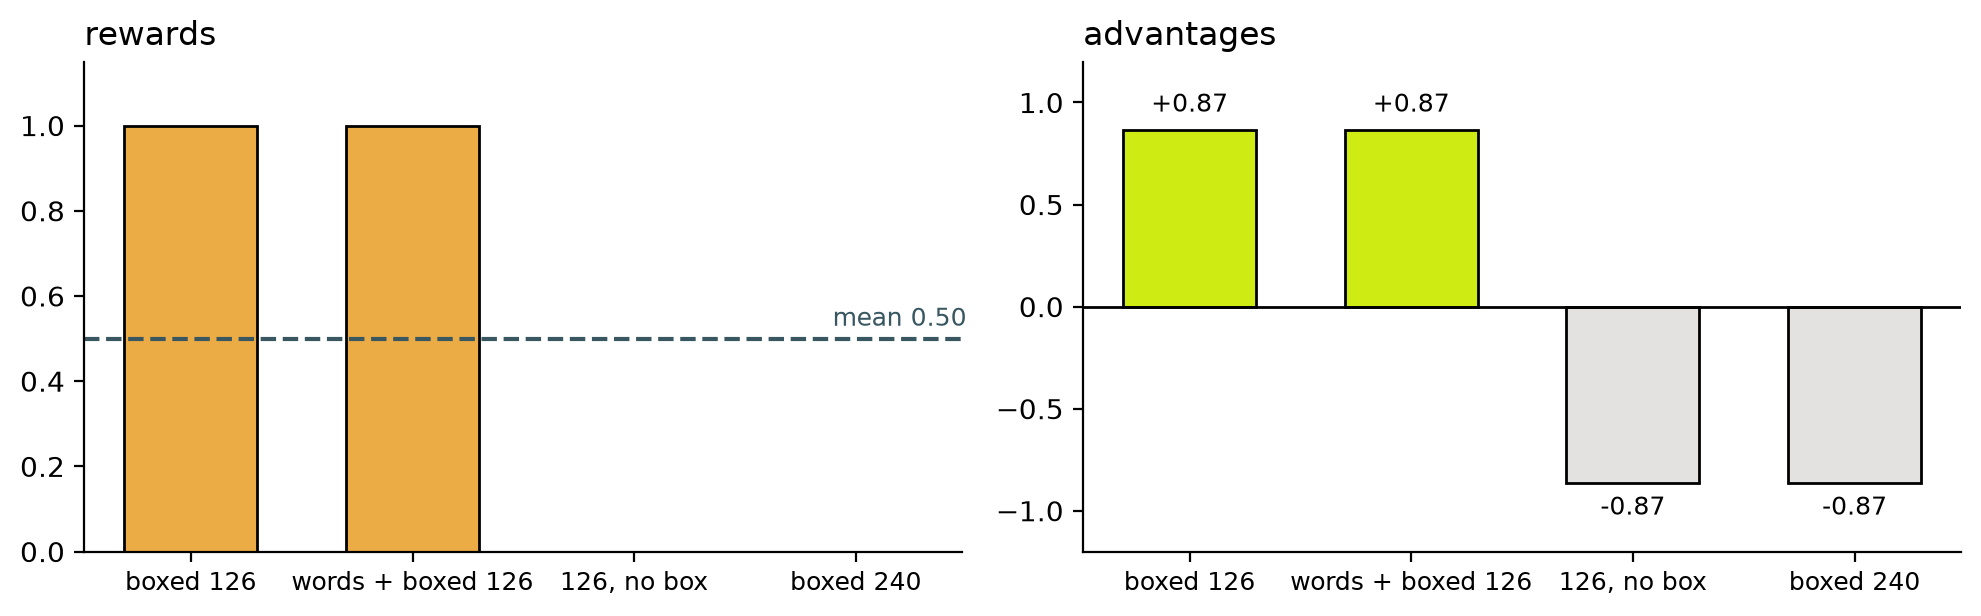

In [18]:
plot_rewards_and_advantages(rewards, labels=["boxed 126", "words + boxed 126", "126, no box", "boxed 240"])

Two rollouts above the mean, two below, symmetric because the group split in half. The size of an advantage depends on how rare the outcome was within the group:

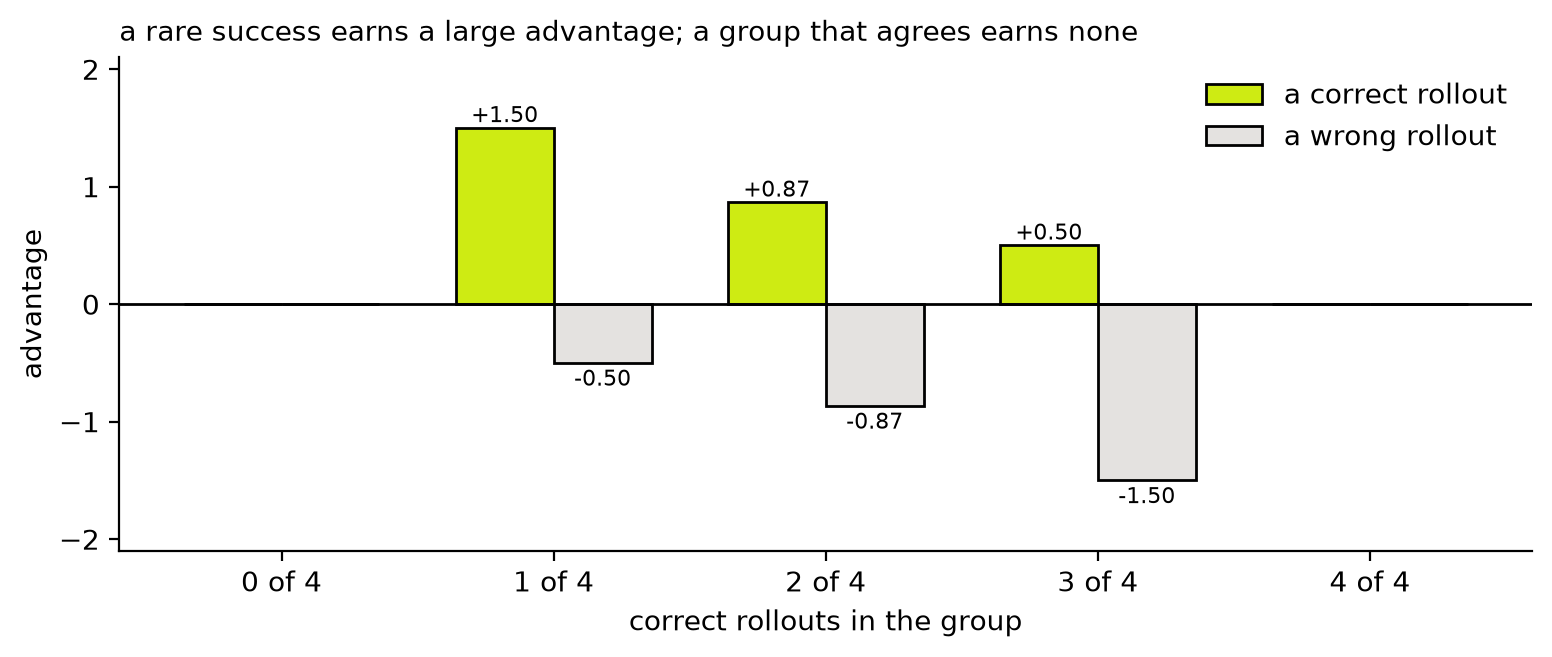

In [19]:
plot_advantage_patterns(n_rollouts=4)

One correct rollout among four earns a large positive advantage and the three failures a mild negative one. Three correct and one wrong is the mirror image. And a group that agrees, all right or all wrong, has every advantage at zero: those problems contribute nothing to training, which is both a weakness (compute spent for no update) and a safety feature (the model is never pushed on problems it already solves or cannot solve at all). The training loop in Step 10 skips the update for such groups.

> **Try it.** Compute `group_advantages([1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0])`. With eight rollouts a lone success is worth even more, and a group of eight is also far less likely to be unanimous. That is the main reason larger groups train better.

## `Step 7`: Sequence log-probabilities

<div align="center"><img src="assets/grpo-step-4.svg" alt="The five-stage GRPO figure with sampling, reward, and compare ticked as done and score highlighted as the current stage" width="1000"/></div>

Stage 4 scores each rollout with the model's own probabilities, the quantity the scoring notebook built as `avg_logprob`. Three things change for training. The log-probabilities of the response tokens are **summed**, not averaged: a rollout earns one reward for the whole sequence, so the score has to be the log-probability of the whole sequence, which is the sum. The function runs **with gradients**, so no `inference_mode`, because this is the quantity training will push on. And it returns a **tensor**, not a Python number, so the gradient has somewhere to flow. Since `sample_response` already returns the token ids and the prompt length, the encoding step goes away too.

In [20]:
def sequence_logprob(model, token_ids, prompt_len):
    logits = model(token_ids.unsqueeze(0)).squeeze(0).float()
    logprobs = torch.log_softmax(logits, dim=-1)
    positions = torch.arange(prompt_len - 1, len(token_ids) - 1, device=token_ids.device)
    next_ids = token_ids[prompt_len:]
    return logprobs[positions, next_ids].sum()

A real rollout ends with the end-of-text token, which the model has to learn to produce, so the hand-written rollouts get one appended. The leading space is there because the prompt ends in "Answer:" and sampled text always starts with a space after it:

In [21]:
def rollout_ids(text):
    return torch.tensor(tokenizer.encode(prompt + " " + text) + [tokenizer.eos_token_id], device=device)

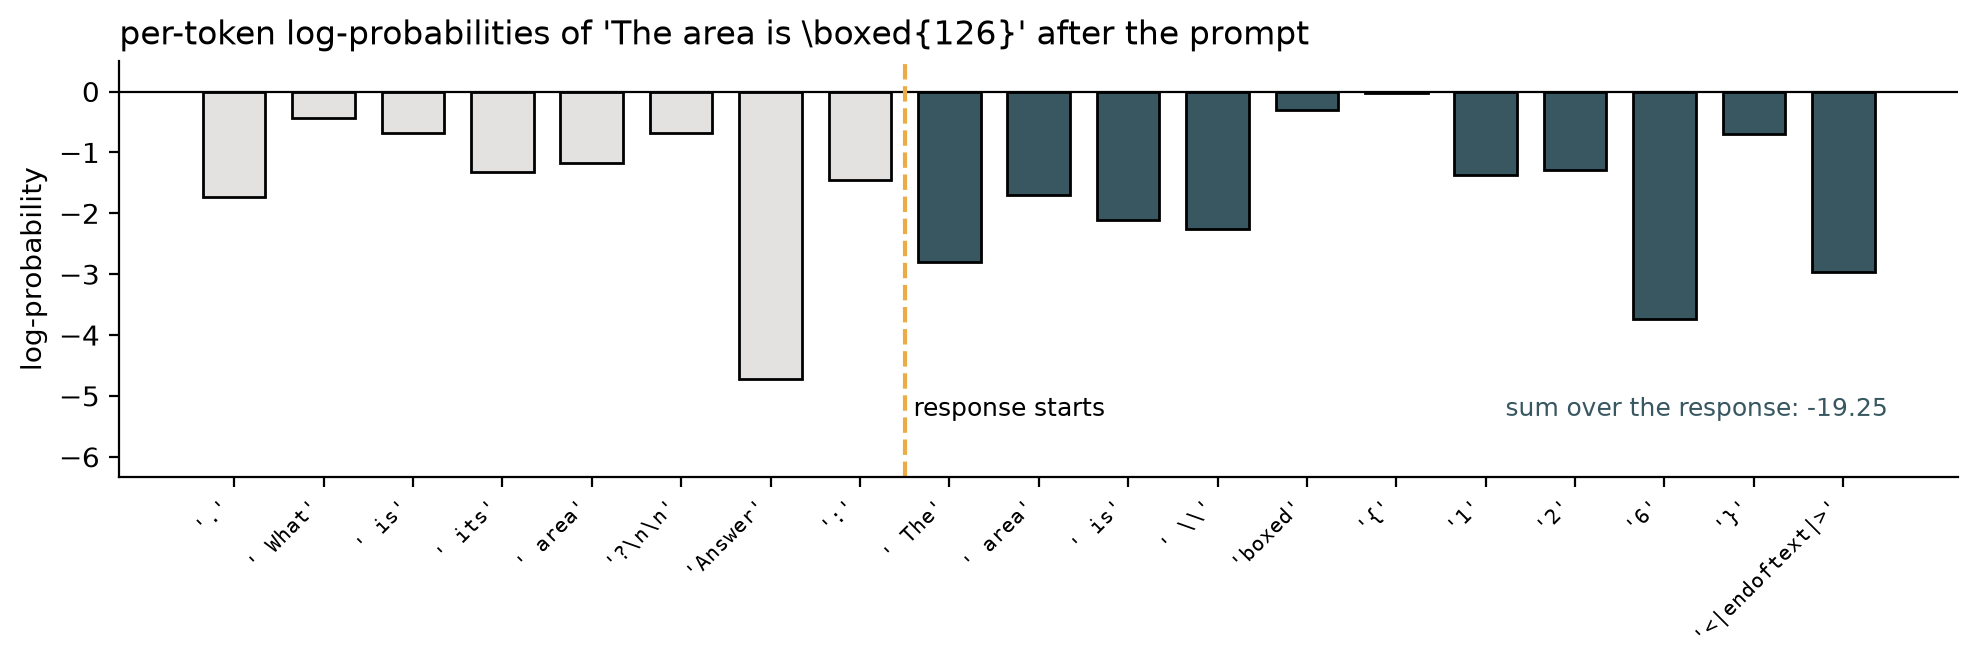

In [22]:
token_ids = rollout_ids(rollouts[1])
with torch.no_grad():
    logits = model(token_ids.unsqueeze(0)).squeeze(0).float()
    per_token = torch.log_softmax(logits, dim=-1)[torch.arange(len(token_ids) - 1, device=device), token_ids[1:]]

tokens = [tokenizer.decode([i]) for i in token_ids[1:].tolist()]
plot_sequence_logprob(tokens, per_token, prompt_len, title="per-token log-probabilities of 'The area is \\boxed{126}' after the prompt")

In [23]:
print(sequence_logprob(model, token_ids, prompt_len))

tensor(-19.2548, device='cuda:0', grad_fn=<SumBackward0>)


The gray bars are the end of the prompt and do not count; the teal bars are the response, and their sum is what the function returns, now with a `grad_fn` attached. The same number comes out of the scoring notebook's `avg_logprob` when its average is multiplied back by the number of response tokens:

In [24]:
response_text = tokenizer.decode(token_ids[prompt_len:].tolist())
print(avg_logprob(model, tokenizer, prompt, response_text, device) * (len(token_ids) - prompt_len))

-19.25069236755371


In [25]:
logps = torch.stack([sequence_logprob(model, rollout_ids(text), prompt_len) for text in rollouts])
for text, logp in zip(rollouts, logps.tolist()):
    print(round(logp, 2), repr(text))

-8.46 '\\boxed{126}'
-19.25 'The area is \\boxed{126}'
-17.44 'The area is 126'
-27.32 'So the area is \\boxed{240}'


A sum over more tokens is a more negative number, so the shortest rollout scores highest and the wordy one lower, and the wrong answer, 240, scores lowest of all because the model found it less plausible. Summed log-probabilities quietly prefer concise responses. That is fine here, and the next notebook has more to say about it.

## `Step 8`: The loss

<div align="center"><img src="assets/grpo-step-5.svg" alt="The five-stage GRPO figure with the first four stages ticked as done and loss highlighted as the current stage" width="1000"/></div>

Stage 5 joins the two numbers each rollout now has, an advantage and a log-probability:

$$\mathcal{L} = -\frac{1}{n}\sum_{i=1}^{n} A_i \cdot \log p(\text{rollout}_i)$$

The last column of the figure is exactly this sum for the four example rollouts: the two products with a positive advantage come out negative, the two with a negative advantage come out positive, and minus their mean is the loss, -3.69. Read the formula as an instruction to the optimizer. For a rollout with a positive advantage, lowering the loss means raising its log-probability: make responses like this one more likely. For a negative advantage, the opposite. The minus sign is there because PyTorch optimizers minimize, and we want the advantage-weighted log-probability to go *up*. The mean over the group keeps the scale independent of the group size. The advantages carry no gradient; they are fixed numbers computed from rewards, so only the log-probabilities feel the update.

In [26]:
def grpo_loss(advantages, logps):
    return -(advantages * logps).mean()

In [27]:
advantages = group_advantages(rewards).to(device)
loss = grpo_loss(advantages, logps)
print(loss)

tensor(-3.6901, device='cuda:0', grad_fn=<NegBackward0>)


Does an update do what the formula promises? One step of plain gradient descent on this group, then re-score the four rollouts. Plain SGD rather than the AdamW optimizer the real loop will use, because an SGD step moves exactly along the gradient and makes the effect easy to read. The weights are snapshotted first so that training can start from the pretrained model afterwards.

In [28]:
snapshot = {name: p.detach().clone() for name, p in model.named_parameters()}

optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
optimizer.zero_grad()
loss.backward()
torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
optimizer.step()

with torch.no_grad():
    logps_after = torch.stack([sequence_logprob(model, rollout_ids(text), prompt_len) for text in rollouts])

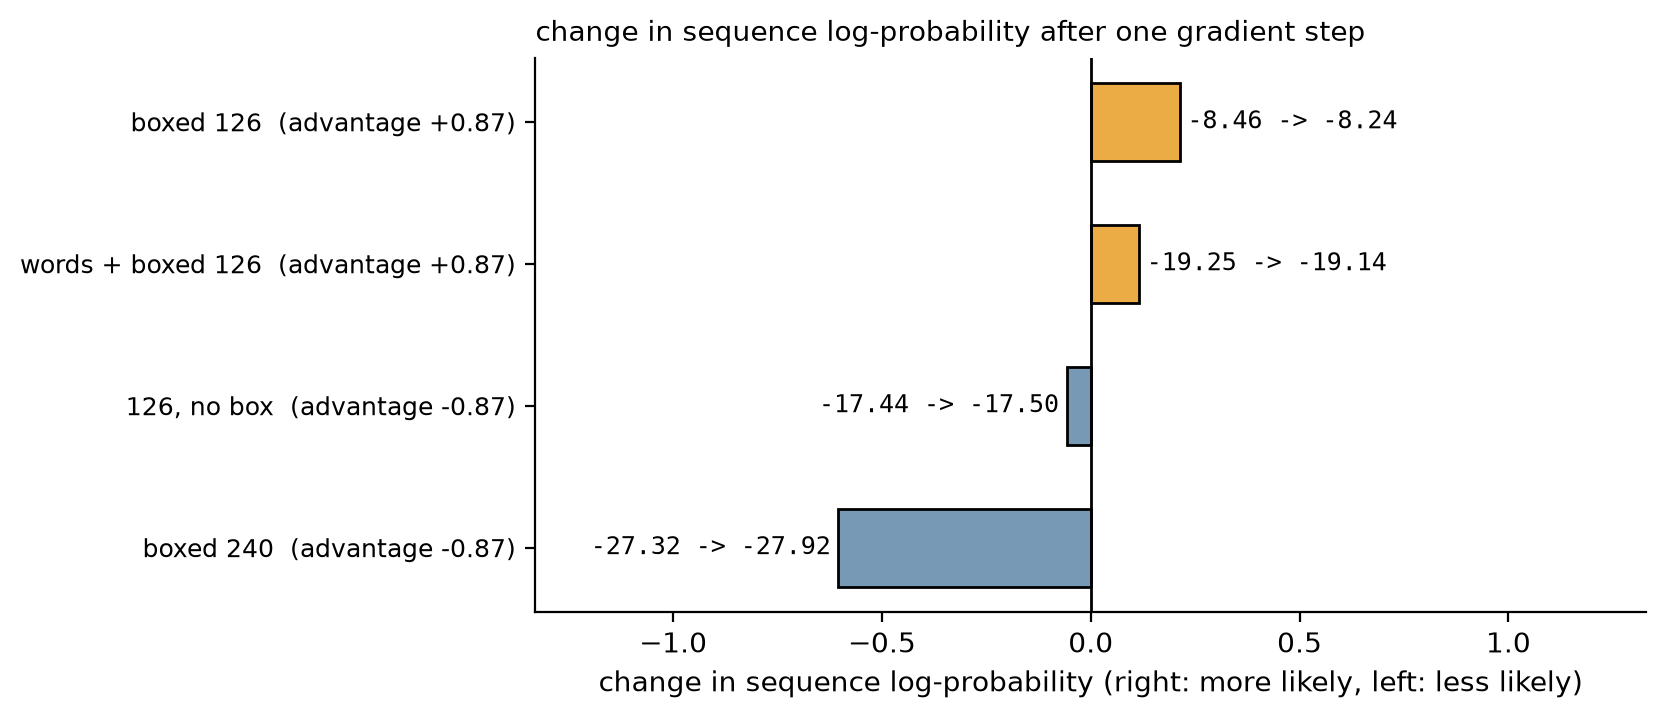

In [29]:
plot_logprob_shift(
    ["boxed 126", "words + boxed 126", "126, no box", "boxed 240"],
    logps.tolist(), logps_after.tolist(), advantages.tolist(),
    title="change in sequence log-probability after one gradient step",
)

The two correct rollouts became more likely and the two others less likely, from a single step, with nothing but a verifier's yes or no steering it. Four more steps on the same group widen every gap:

In [30]:
for step in range(4):
    optimizer.zero_grad()
    logps_now = torch.stack([sequence_logprob(model, rollout_ids(text), prompt_len) for text in rollouts])
    grpo_loss(advantages, logps_now).backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    print("after update", step + 2, [round(v, 2) for v in logps_now.tolist()])

after update 2 [-8.24, -19.14, -17.5, -27.92]
after update 3 [-7.99, -19.02, -17.63, -28.69]
after update 4 [-7.72, -18.9, -17.8, -29.52]
after update 5 [-7.44, -18.81, -17.99, -30.37]


In [31]:
with torch.no_grad():
    for name, p in model.named_parameters():
        p.copy_(snapshot[name])  # back to the pretrained weights
del snapshot, optimizer

That is the entire learning signal of GRPO. No value network, no learned reward model, no second copy of the policy. The verifier decides which rollouts to favor, the group decides by how much, and the log-probability gives the gradient a handle on the weights.

## `Step 9`: One GRPO step

All five stages are now done, and they go into one function. To be precise about what a step is: one GRPO step takes **one problem** from the training set, samples a group of `n_rollouts` responses to that one problem, gives each response its own reward and advantage, scores each, and forms one loss from them. The training loop in Step 10 will call this once per step, moving to the next problem each time. The function returns the loss tensor along with everything worth logging; backward and the optimizer step stay outside, where a PyTorch training loop expects them. One shortcut: when every rollout earned the same reward the advantages are all zero and the loss would be zero too, so the function returns without the expensive scoring passes.

<div align="center"><img src="assets/grpo-step-done.svg" alt="The five-stage GRPO figure with all five stages ticked as done" width="1000"/></div>

The same step, animated, on the rectangle problem with the four example rollouts:

<div align="center"><img src="assets/grpo-step.gif" alt="Animation of one GRPO step on one problem, the rectangle problem: four rollouts appear one by one, then a row of rewards, a row of advantages, a row of log-probabilities, the loss, and finally the log-probabilities after the update with the two correct rollouts up and the two others down" width="900"/></div>

In [32]:
def grpo_step(
    model, tokenizer, example, device, n_rollouts=4, max_new_tokens=512, temperature=0.8, top_p=0.9
):
    prompt = render_math_prompt(example["problem"], MATH_PROMPT)
    rollouts, rewards = [], []
    for _ in range(n_rollouts):
        token_ids, prompt_len, text = sample_response(
            model, tokenizer, prompt, device, max_new_tokens, temperature, top_p
        )
        rollouts.append((token_ids, prompt_len, text))
        rewards.append(correctness_reward(text, example["answer"]))
    advantages = group_advantages(rewards).to(device)

    out = {
        "texts": [text for _, _, text in rollouts],
        "lengths": [len(token_ids) - prompt_len for token_ids, prompt_len, _ in rollouts],
        "rewards": rewards,
        "advantages": advantages.tolist(),
        "loss": None,
    }
    if all(r == rewards[0] for r in rewards):
        return out  # every rollout got the same reward: nothing to compare, nothing to learn here

    logps = torch.stack([sequence_logprob(model, token_ids, prompt_len) for token_ids, prompt_len, _ in rollouts])
    out["loss"] = grpo_loss(advantages, logps)
    return out

In [33]:
torch.manual_seed(1)
out = grpo_step(model, tokenizer, example, device, n_rollouts=4)

print("rewards:", out["rewards"])
print("advantages:", [round(a, 2) for a in out["advantages"]])
print("lengths:", out["lengths"])
print("loss:", out["loss"])

rewards: [0.0, 1.0, 0.0, 1.0]
advantages: [-0.87, 0.87, -0.87, 0.87]
lengths: [8, 325, 7, 384]
loss: tensor(5.9272, device='cuda:0', grad_fn=<NegBackward0>)


In [34]:
for text in out["texts"]:
    print(repr(text[:90]))

' \\boxed{160}'
" Let's solve the problem step by step.\n\n1. **Define the variables:**\n   - Let \\( w \\) be t"
' \\boxed{56}'
" \nLet's solve the problem step by step.\n\n1. **Define the variables:**\n   - Let \\( w \\) be "


Two bare guesses and two worked solutions, and the verifier liked the worked ones. The loss is positive this time: the favored rollouts are the long ones, with very negative log-probabilities, so the advantage-weighted sum comes out negative and the minus sign flips it. The sign of the loss means little on its own. What matters is its gradient.

A group that agrees produces no loss at all:

In [35]:
torch.manual_seed(2)
out = grpo_step(model, tokenizer, example, device, n_rollouts=4)
print("rewards:", out["rewards"], "loss:", out["loss"])

rewards: [0.0, 0.0, 0.0, 0.0] loss: None


## `Step 10`: The training loop

Everything around `grpo_step` is the standard PyTorch loop: zero the gradients, compute the loss, backward, clip, optimizer step, log. This loop is RLVR end to end: the data is problems with checkable answers, the reward is the verifier, and GRPO is the update rule. Each step here uses a single problem; larger implementations batch several problems per step, each with its own group, which changes memory and speed but not the method. Two choices worth naming. The optimizer is AdamW at a learning rate of 1e-6, ten times smaller than a typical fine-tuning rate, because a reinforcement learning signal is noisy and the pretrained weights are worth protecting; at 1e-5 the same run grew its responses to the token limit within a few dozen steps and its accuracy swung from one checkpoint to the next. And the gradient norm is clipped to 1.0, because one group with an unlucky sampling draw can produce a gradient many times larger than usual, and a single such step can wreck a run. Metrics go to a JSON-lines file and the weights to a checkpoint every so often.

In [36]:
import json
import time
from pathlib import Path


def train_grpo(
    model,
    tokenizer,
    train_data,
    device,
    steps=50,
    n_rollouts=4,
    max_new_tokens=512,
    temperature=0.8,
    top_p=0.9,
    lr=1e-6,
    log_path=None,
    checkpoint_every=0,
    checkpoint_dir="checkpoints",
    sample_every=10,
):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = []
    if log_path:
        Path(log_path).parent.mkdir(parents=True, exist_ok=True)
        Path(log_path).write_text("", encoding="utf-8")

    start = time.time()
    for step in range(1, steps + 1):
        example = train_data[(step - 1) % len(train_data)]
        optimizer.zero_grad()
        out = grpo_step(model, tokenizer, example, device, n_rollouts, max_new_tokens, temperature, top_p)
        if out["loss"] is not None:
            out["loss"].backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # one outsized gradient must not derail the run
            optimizer.step()

        metrics = {
            "step": step,
            "reward": sum(out["rewards"]) / n_rollouts,
            "length": sum(out["lengths"]) / n_rollouts,
            "loss": out["loss"].item() if out["loss"] is not None else 0.0,
            "updated": out["loss"] is not None,
            "seconds": time.time() - start,
        }
        history.append(metrics)
        if log_path:
            with open(log_path, "a", encoding="utf-8") as f:
                f.write(json.dumps(metrics) + "\n")
        print(
            f"step {step}/{steps}",
            f"reward {metrics['reward']:.2f}",
            f"length {metrics['length']:.0f}",
            f"loss {metrics['loss']:.3f}",
        )
        if sample_every and step % sample_every == 0:
            print("sample:", repr(out["texts"][0][:160]))
        if checkpoint_every and step % checkpoint_every == 0:
            save_checkpoint(model, Path(checkpoint_dir) / f"grpo-step{step:04d}.pt")
    return history


def save_checkpoint(model, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    module = getattr(model, "_orig_mod", model)  # a compiled model wraps the real one; save the real one's keys
    torch.save(module.state_dict(), path)
    print("saved", path)
    return path

One hundred steps, four rollouts per problem, at most 512 new tokens per rollout, with a checkpoint every 25 steps. Four rollouts is the smallest group that still gives the comparison something to work with, and it keeps peak memory under 20 GB, so the run fits a 24 GB GPU. On the L40S it takes about ten minutes. Watch three things in the log: the average reward, which should drift up; the response length, which grows as the model discovers that working things out pays; and the sample every ten steps, to check that the text is still coherent.

In [37]:
torch.manual_seed(0)
history = train_grpo(
    model,
    tokenizer,
    math_train,
    device,
    steps=100,
    n_rollouts=4,
    max_new_tokens=512,
    log_path="outputs/grpo_notebook.jsonl",
    checkpoint_every=25,
    checkpoint_dir="checkpoints/notebook",
)

step 1/100 reward 0.25 length 6 loss -0.194
step 2/100 reward 0.00 length 10 loss 0.000
step 3/100 reward 0.25 length 129 loss 13.886
step 4/100 reward 0.25 length 44 loss 9.573
step 5/100 reward 0.00 length 133 loss 0.000
step 6/100 reward 0.00 length 8 loss 0.000
step 7/100 reward 0.00 length 228 loss 0.000
step 8/100 reward 0.00 length 6 loss 0.000
step 9/100 reward 1.00 length 10 loss 0.000
step 10/100 reward 0.25 length 14 loss 0.582
sample: ' \\boxed{2 \\frac{1}{4}} cups of flour'
step 11/100 reward 0.00 length 11 loss 0.000
step 12/100 reward 0.00 length 134 loss 0.000
step 13/100 reward 0.25 length 127 loss -9.816
step 14/100 reward 0.00 length 162 loss 0.000
step 15/100 reward 0.00 length 161 loss 0.000
step 16/100 reward 0.00 length 389 loss 0.000
step 17/100 reward 0.00 length 332 loss 0.000
step 18/100 reward 0.00 length 7 loss 0.000
step 19/100 reward 0.00 length 6 loss 0.000
step 20/100 reward 0.00 length 64 loss 0.000
sample: ' To find the sum of the numeric values of th

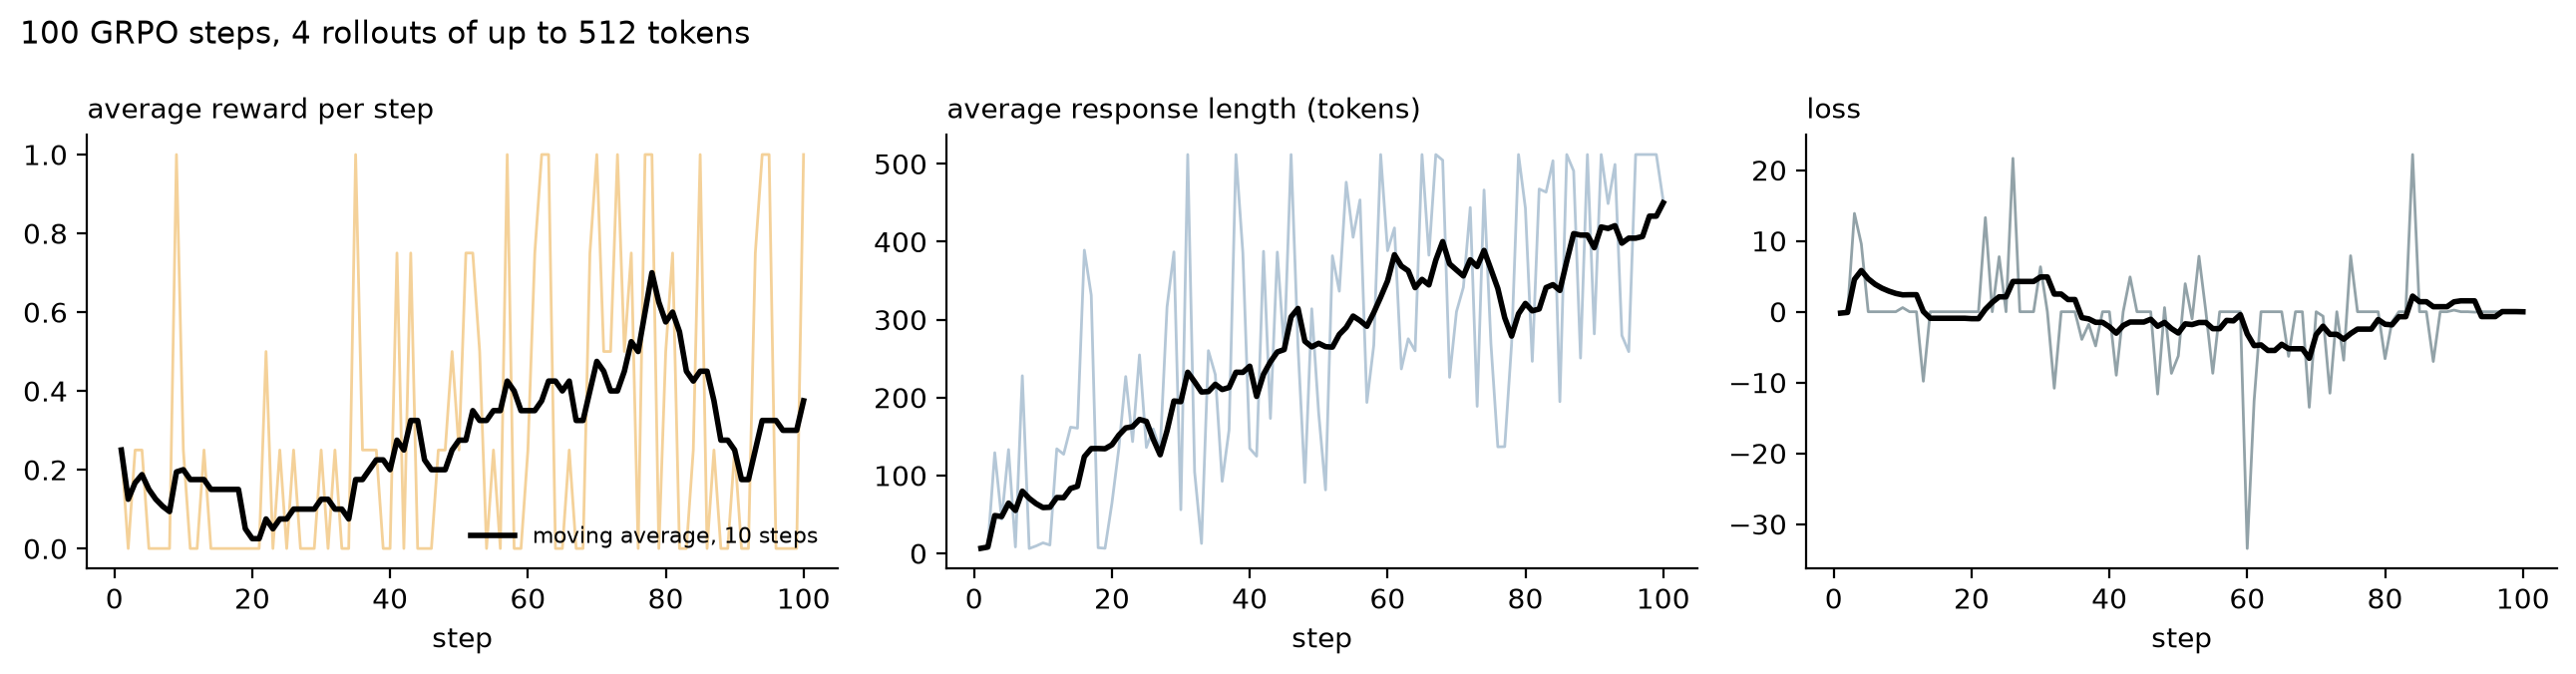

peak memory: 18.2 GB
steps with an update: 37 of 100


In [38]:
plot_training_metrics(history, window=10, title="100 GRPO steps, 4 rollouts of up to 512 tokens")
print("peak memory:", round(peak_memory_gb(device), 1), "GB")
print("steps with an update:", sum(h["updated"] for h in history), "of", len(history))

Read the three panels together. In the first twenty steps the average reward sat around 0.1 and only five steps carried an update: the base model mostly answered with a bare number, bare numbers are mostly wrong, and a group of four wrong answers is unanimous, so nothing happened. The few groups that did contain a worked, correct solution pushed the model toward writing more, and from step 20 on the response length climbed from about a hundred tokens to over four hundred while the reward rose with it, reaching about 0.5 over steps 60 to 80. The loss panel is the least useful of the three: its sign and size depend on which rollouts happened to be favored, which is why training curves for reinforcement learning are read through the reward, not the loss.

Two things to keep an eye on. Only 37 of the 100 steps changed the weights; the rest were unanimous groups, the price of a small group. And the response length kept growing in the last twenty steps while the reward slipped, because a response that runs into the 512-token cap never reaches a box and earns nothing. That is the first sign of the instability the next notebook deals with.

## `Step 11`: Did it work?

The rectangle problem first, greedy, with the plain prompt that never asked for any work:

In [39]:
trained_answer = generate_text(model, tokenizer, prompt, device, max_new_tokens=400, stream=True)

 Let's solve the problem step by step.

**Step 1: Define the Variables**
- Let \( w \) be the width of the rectangle.
- Then, the length \( l \) is \( 2w + 4 \).

**Step 2: Use the Perimeter Formula**
The perimeter \( P \) of a rectangle is given by:
\[
P = 2(l + w)
\]
Given that the perimeter is 50:
\[
2((2w + 4) + w) = 50
\]

**Step 3: Simplify the Equation**
\[
2(3w + 4) = 50
\]
\[
6w + 8 = 50
\]

**Step 4: Solve for \( w \)**
\[
6w = 50 - 8
\]
\[
6w = 42
\]
\[
w = 7
\]

**Step 5: Find the Length \( l \)**
\[
l = 2w + 4 = 2(7) + 4 = 14 + 4 = 18
\]

**Step 6: Calculate the Area**
The area \( A \) of a rectangle is:
\[
A = l \times w = 18 \times 7 = 126
\]

**Final Answer:**
\[
\boxed{126}
\]

In [40]:
print(grade(last_boxed(trained_answer), answer))

True


Then the same fifty problems as the baseline from Step 2, with the same greedy decoding and the same prompt. The halfway checkpoint first, loaded on top of the pretrained weights through `load_qwen3`, back in `bfloat16`, exactly as a reader with a saved checkpoint would do it; then the model in memory after all one hundred steps:

In [41]:
halfway, _ = load_qwen3("base", device=device, compile=True, checkpoint="checkpoints/notebook/grpo-step0050.pt")
results["after 50 GRPO steps"] = evaluate_math(halfway, tokenizer, device, subset, max_new_tokens=1024)
del halfway

10/50 correct so far: 2
20/50 correct so far: 4
30/50 correct so far: 4
40/50 correct so far: 7
50/50 correct so far: 9
accuracy: 18.0% (9/50)
average response: 97 tokens
time: 0.8 min


In [42]:
results["after 100 GRPO steps"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024)

10/50 correct so far: 5
20/50 correct so far: 8
30/50 correct so far: 13
40/50 correct so far: 19
50/50 correct so far: 25
accuracy: 50.0% (25/50)
average response: 468 tokens
time: 2.2 min


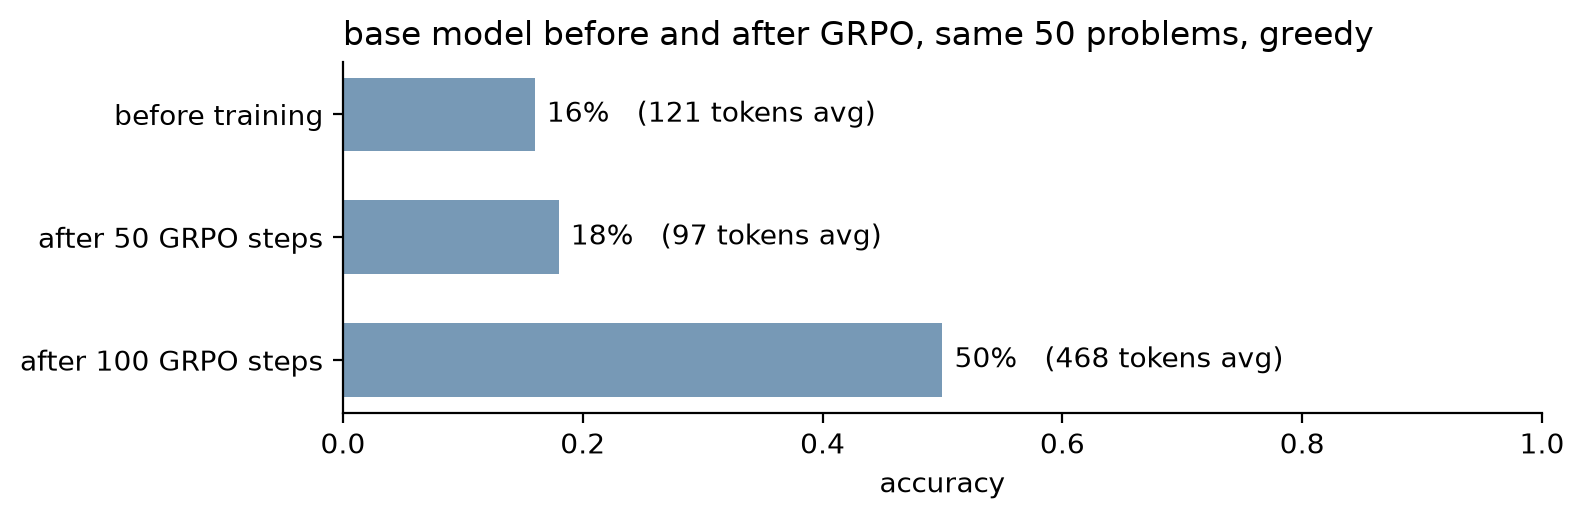

In [43]:
plot_accuracy_comparison(results, title=f"base model before and after GRPO, same {N} problems, greedy")

From 16 percent to 50 percent on the same fifty problems, with the same prompt and greedy decoding, and the model was never shown a single solution. The halfway checkpoint tells the more interesting half of the story: at step 50 accuracy had barely moved and responses were still short, even though the reward on the training problems was already climbing. The gain arrived in the second half, once a worked solution had become the model's default rather than an occasional sample, and the average response grew from about a hundred tokens to nearly five hundred. In the math verifier notebook the post-trained reasoning variant of this same model scored 48 percent on this slice with about 1,350 tokens per problem. One hundred GRPO steps on one GPU landed in the same neighborhood with a third of the tokens.

Treat the exact number with care. This is one seed and fifty problems. The same configuration run from the command line, with a different random state, reached 32 percent at step 100, and a small change to the learning rate moves the outcome by as much again. The shape of the result is reliable: the base model learns to work problems out, and accuracy follows. The final percentage is not.

## `Step 12`: Promote it to the toolbox

`sample_response`, `correctness_reward`, `group_advantages`, `sequence_logprob`, `grpo_loss`, `grpo_step`, `train_grpo`, and `save_checkpoint` now live in `reasoning_utils/grpo.py`, exactly as written above, and `load_math_train` in `reasoning_utils/data.py`. `scripts/train_grpo.py` runs the same loop from the command line, with the same defaults, and `scripts/evaluate_math500.py` gained a `--checkpoint` flag, so a trained model can be measured on the full benchmark or fed into any of the earlier notebooks' methods:

```bash
uv run scripts/evaluate_math500.py --model base --n 500 --compile --checkpoint checkpoints/notebook/grpo-step0100.pt
uv run scripts/train_grpo.py
```

The first command evaluates the checkpoint this notebook just saved. The second repeats the training from the command line with the same defaults; it writes its checkpoints to `checkpoints/grpo_100x4/` and its metrics to `outputs/grpo_100x4.jsonl`.

On the full benchmark, a command-line run with the notebook's settings, four rollouts and one hundred steps at 1e-6, scored 28.4 percent on all 500 problems with 294 tokens per response, against 14.8 percent for the base model in the math verifier notebook and 50.6 percent for the post-trained reasoning variant. The faster run at 3e-6, taken at its best checkpoint (step 75), reached 45.2 percent with 647 tokens per response, a few points short of the reasoning variant from one hundred steps on one GPU, and with the dip at step 100 as the warning that it was already past its safe range. The full benchmark is the number to quote; the fifty-problem slice in this notebook is for watching the training happen.

In [44]:
from reasoning_utils import grpo_loss as grpo_loss_toolbox
from reasoning_utils import sequence_logprob as sequence_logprob_toolbox

print(grpo_loss_toolbox(advantages, logps).item() == grpo_loss(advantages, logps).item())
print(sequence_logprob_toolbox(model, token_ids, prompt_len).item() == sequence_logprob(model, token_ids, prompt_len).item())

True
True


## Summary

- Reinforcement learning for a language model is a loop: sample, judge, move the weights toward what the judge liked. With a verifier as the judge the loop needs no human labels and no reward model. That is RLVR, reinforcement learning with verifiable rewards, and GRPO is the algorithm that does the moving.
- A GRPO step samples a **group** of rollouts for one problem, rewards each with the verifier, and converts the rewards into **advantages** by centering and scaling within the group. A unanimous group carries no signal.
- Each rollout is scored by its **sequence log-probability**, the sum of its response tokens' log-probabilities with gradients attached, the same quantity the scoring notebook averaged.
- The loss is minus the mean of advantage times log-probability. Lowering it raises the probability of rollouts that beat their group and lowers the rest. One gradient step is enough to see it happen.
- Training is the ordinary PyTorch loop around that step, with `float32` weights, AdamW at a small learning rate, and gradient clipping.
- One hundred steps on one GPU, four rollouts per problem, took the base model from 16 to 50 percent on fifty MATH-500 problems, with the plain prompt and no demonstrations. The outcome is sensitive to the learning rate and to the seed, and the response length drifts upward as training goes on. The next notebook is about what goes wrong when training runs longer, and the fixes the current open models use.

## Further reading

- [DeepSeekMath](https://arxiv.org/abs/2402.03300) (Shao et al., 2024), where GRPO was introduced
- [DeepSeek-R1](https://arxiv.org/abs/2501.12948) (DeepSeek-AI, 2025), reinforcement learning with verifiable rewards on a base model, and what emerged
- [Training language models to follow instructions with human feedback](https://arxiv.org/abs/2203.02155) (Ouyang et al., 2022), the original reward-model recipe
- [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347) (Schulman et al., 2017), the algorithm GRPO simplifies
- [Tulu 3](https://arxiv.org/abs/2411.15124) (Lambert et al., 2024), verifiable rewards as a general post-training stage
- [`torch.no_grad`](https://docs.pytorch.org/docs/stable/generated/torch.no_grad.html) and [`torch.inference_mode`](https://docs.pytorch.org/docs/stable/generated/torch.inference_mode.html) documentation, and why only one of them is right for sampling rollouts

Next up in this track: stabilizing GRPO. Clipping, a reference model, and the length corrections that keep a longer run from collapsing.